## HW 7 Problem 3<br>
Filippa Mudsam

**c)**

### Original way with exponential gaps

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson

In [2]:
rng = np.random.default_rng()

lam = 4
t = 1
nsim = int(2*10**5)

In [3]:
N1 = np.zeros(nsim, dtype = int)
arrivals1 = []

for j in range(nsim):
    T = 0
    times = []
    while True:
        T -= np.log(rng.random()) / lam
        if T > t:
            break
        times.append(T)
    arrivals1.append(np.array(times))
    N1[j] = len(times)

### Poisson count Using uniform joint densities

In [4]:
N2 = np.zeros(nsim, dtype = int)
arrivals2 = []
U = rng.random(nsim)

for j in range(nsim):
    p = np.exp(-lam*t)
    s = p
    i = 0
    while True:
        if U[j] < s:
            N2[j] = i
            break
        else:
            i += 1
            p = lam*t*p / i
            s += p
    arrivals2.append(np.sort(t*rng.random(N2[j])))


### Histograms

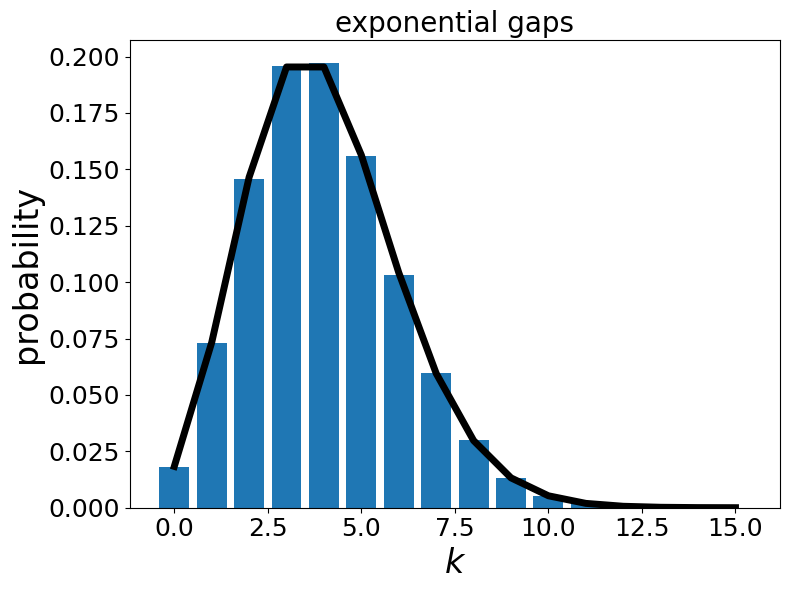

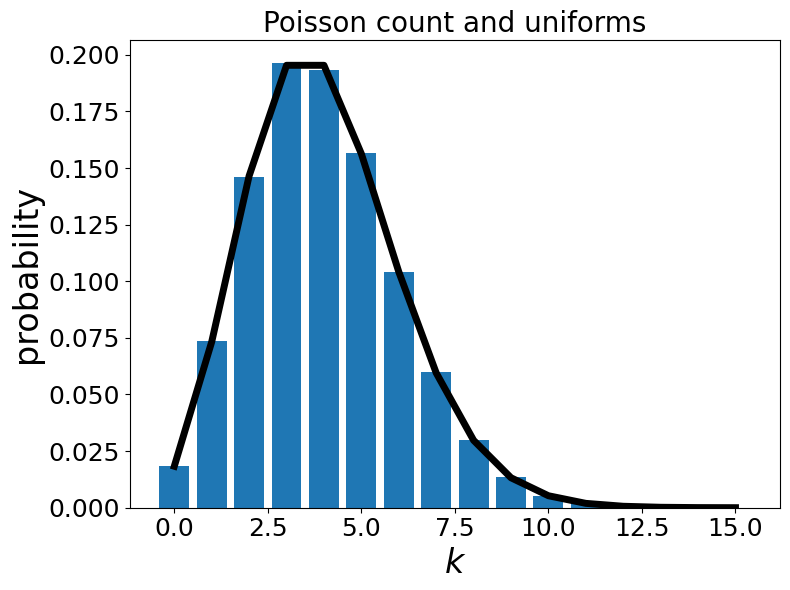

mean :  4.00281   variance = 3.9898721039000007
mean = 4.002045   variance = 4.020680817975


In [5]:
k = np.arange(0, 16)
f_poisson = poisson.pmf(k, lam*t)

plt.figure(1, figsize=(8, 6))
plt.bar(k, np.bincount(N1, minlength=16)[:16]/nsim)
plt.plot(k, f_poisson, 'k', linewidth=5)
plt.title('exponential gaps', fontsize=20)
plt.tick_params(labelsize=18)
plt.xlabel('$k$', fontsize=24)
plt.ylabel('probability', fontsize=24)
plt.tight_layout()

plt.figure(2, figsize=(8, 6))
plt.bar(k, np.bincount(N2, minlength=16)[:16]/nsim)
plt.plot(k, f_poisson, 'k', linewidth=5)
plt.title('Poisson count and uniforms', fontsize=20)
plt.tick_params(labelsize=18)
plt.xlabel('$k$', fontsize=24)
plt.ylabel('probability', fontsize=24)
plt.tight_layout()
plt.show()

print('mean : ', np.mean(N1), '  variance =', np.var(N1))
print('mean =', np.mean(N2), '  variance =', np.var(N2))

### Ten Realizations

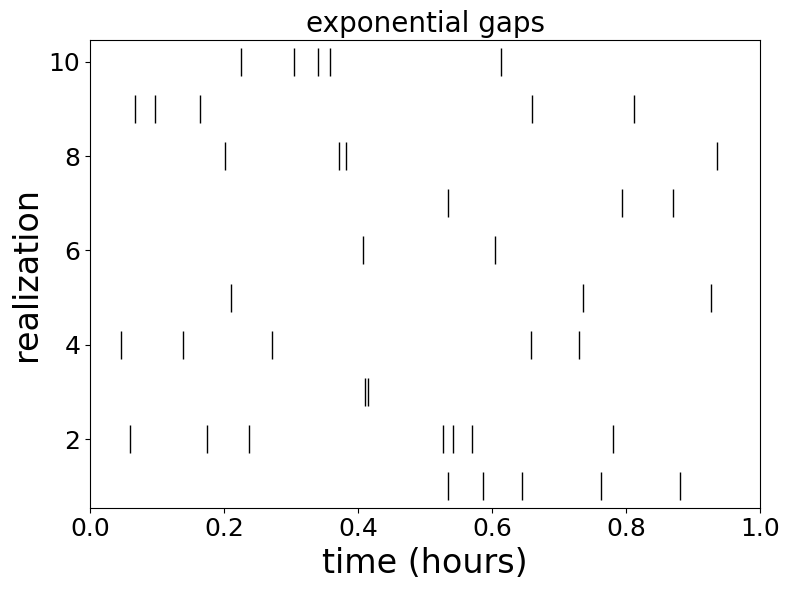

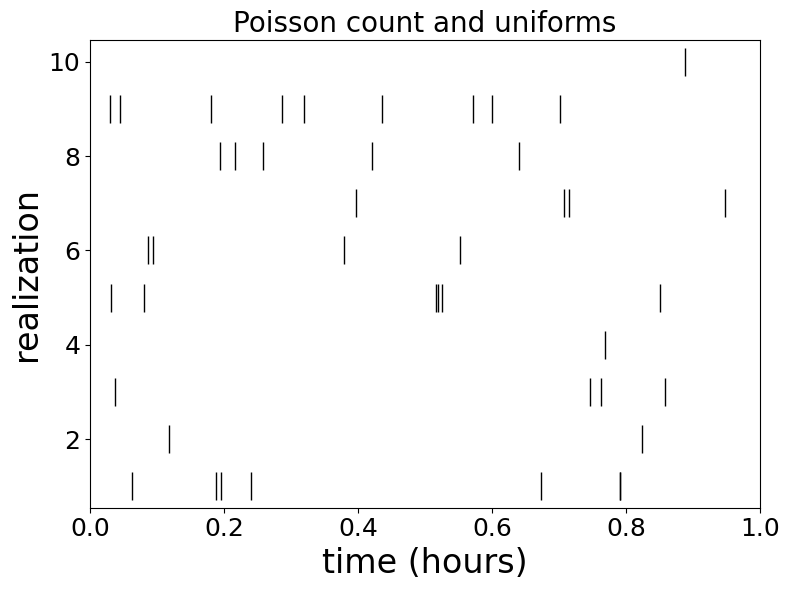

In [6]:
plt.figure(3, figsize=(8, 6))
for j in range(10):
    plt.plot(arrivals1[j], (j + 1)*np.ones(N1[j]), 'k|',  markersize=20)
plt.xlim([0, t])
plt.title('exponential gaps', fontsize=20)
plt.tick_params(labelsize=18)
plt.xlabel('time (hours)', fontsize=24)
plt.ylabel('realization', fontsize=24)
plt.tight_layout()

plt.figure(4, figsize=(8, 6))
for j in range(10):
    plt.plot(arrivals2[j], (j + 1)*np.ones(N2[j]), 'k|', markersize=20)
plt.xlim([0, t])
plt.title('Poisson count and uniforms', fontsize=20)
plt.tick_params(labelsize=18)
plt.xlabel('time (hours)', fontsize=24)
plt.ylabel('realization', fontsize=24)
plt.tight_layout()
plt.show()

### Histogram of T3 vs Gamma(4,3)

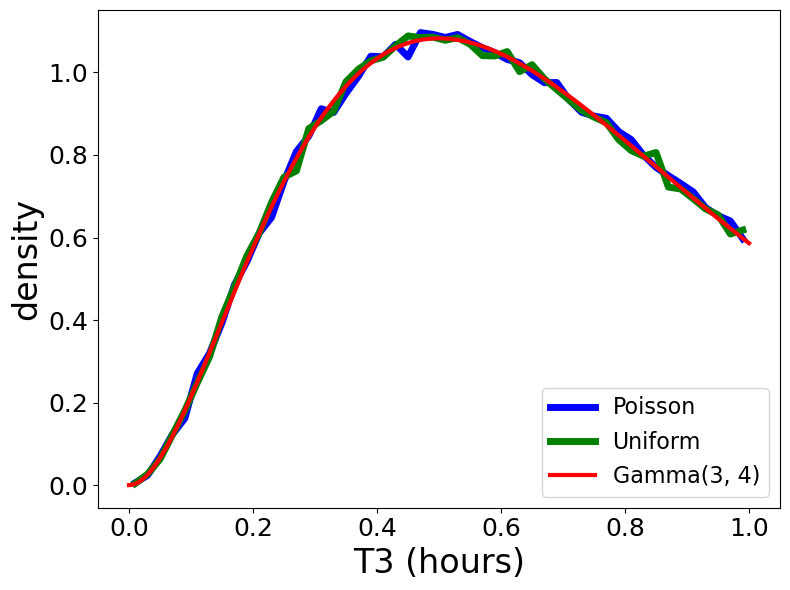

In [7]:
T3_way1 = []
T3_way2 = []
for j in range(nsim):
    if N1[j] >= 3:
        T3_way1.append(arrivals1[j][2])
    if N2[j] >= 3:
        T3_way2.append(arrivals2[j][2])

bw = 0.02
edges = np.arange(0, t + bw/2, bw)
centers = edges[:-1] + bw/2
cts1, _ = np.histogram(T3_way1, bins=edges)
cts2, _ = np.histogram(T3_way2, bins=edges)

x = np.linspace(0, t, 500)
f_gamma = lam*np.exp(-lam*x)*(lam*x)**2/2   # Gamma(3, lam) density

plt.figure(5, figsize=(8, 6))
plt.plot(centers, cts1/(nsim*bw), 'b', linewidth=5, label='Poisson')
plt.plot(centers, cts2/(nsim*bw), 'g', linewidth=5, label='Uniform')
plt.plot(x, f_gamma, 'r', linewidth=3, label='Gamma(3, 4)')
plt.legend(fontsize=16)
plt.tick_params(labelsize=18)
plt.xlabel('T3 (hours)', fontsize=24)
plt.ylabel('density', fontsize=24)
plt.tight_layout()
plt.show()

estimate P(N(12) = 0), E[T1] and the correlation between the counts in the first and second half hour (over all hours).

In [8]:
none1 = []   # 1 if no meteor in the first half hour, else 0
T1_p = []
none2 = []
T1_u = []
for j in range(nsim):
    if N1[j] == 3:
        none1.append(np.sum(arrivals1[j] <= 0.5) == 0)
        T1_p.append(arrivals1[j][0])
    if N2[j] == 3:
        none2.append(np.sum(arrivals2[j] <= 0.5) == 0)
        T1_u.append(arrivals2[j][0])

print('P(N(1/2) = 0) =', np.mean(none1), '  E[T1] =', np.mean(T1_p))
print('P(N(1/2) = 0) =', np.mean(none2), '  E[T1] =', np.mean(T1_u))

P(N(1/2) = 0) = 0.12477335989172349   E[T1] = 0.2506192458652752
P(N(1/2) = 0) = 0.12471701472795259   E[T1] = 0.2502352963351484


Finally, compute the total variation distance between Binomial(t/∆t, λ∆t) and Poisson(λt) for t = 1 and ∆t = 1/10, . . . , 1/2000, and fit its slope against ∆t on log–log axes.

slope = 1.0359237308411344


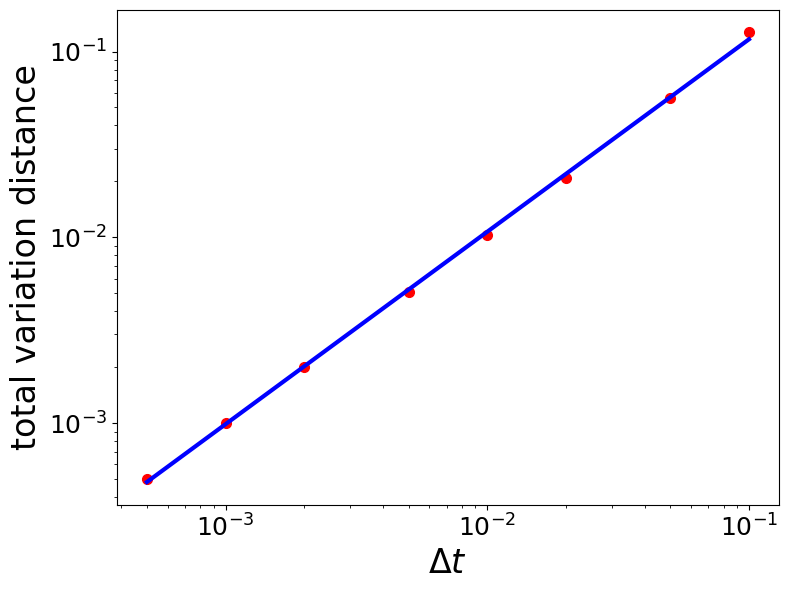

In [9]:
n_steps = np.array([10, 20, 50, 100, 200, 500, 1000, 2000])   # t/dt
dt = t/n_steps
tv = np.zeros(len(n_steps))

for j in range(len(n_steps)):
    k = np.arange(0, 60)   # Poisson(4) mass beyond 60 is negligible
    tv[j] = 0.5*np.sum(np.abs(binom.pmf(k, n_steps[j], lam*dt[j]) - poisson.pmf(k, lam*t)))

# fit a line to log(tv) vs log(dt)
slope, intercept = np.polyfit(np.log(dt), np.log(tv), 1)
print('slope =', slope)

plt.figure(6, figsize=(8, 6))
plt.loglog(dt, tv, 'r.', markersize=14)
plt.loglog(dt, np.exp(intercept)*dt**slope, 'b', linewidth=3)
plt.tick_params(labelsize=18)
plt.xlabel('$\\Delta t$', fontsize=24)
plt.ylabel('total variation distance', fontsize=24)
plt.tight_layout()
plt.show()